# Forecasted exogenous variables

Many useful exogenous variables are not known in advance: they are forecasts themselves. Weather forecasts, market price estimates, sales plans or production schedules are only available as predictions when the forecast is made, and they are **revised over time**: the value for next Friday published on Wednesday differs from the one published on Thursday, and both differ from the value finally observed.

**The problem**

The history of a forecasted variable has two timestamps: the time the value refers to and the time it was published. Datasets usually keep a single value per timestamp, most often the observed one. If a backtest uses it to make predictions, each fold uses values that were not available when that prediction would have been made (**look-ahead bias**). The metrics then overestimate the performance the model will have in production, and the bias grows with the error of the forecasts of the variable, which usually increases with the horizon.

**The solution**

Each prediction of the backtest must use only the values that were available when it was made. In skforecast this takes two steps, with no special arguments:

1. **Build a point-in-time exogenous variable**: for each timestamp, keep the last value published before the moment the prediction is made in production. The result is an ordinary exogenous column, built with a few lines of pandas.
2. **Reproduce the production process in the backtest**: [`TimeSeriesFold`](https://skforecast.org/latest/api/model_selection#skforecast.model_selection._split.TimeSeriesFold) defines when each prediction is made and what it covers, with `steps` (horizon), `gap` (time between the last observed value and the first predicted one), `fold_stride` (how often predictions are made) and `refit`.

Since the result is a regular `exog`, it works with every forecaster, every backtesting and hyperparameter search function, and with `predict()` in production. The model can be trained with the observed values of the variable or with the forecasts that were available at each moment: the guide compares both options.

This guide uses temperature forecasts as an example, with the `vic_electricity` dataset, but the same approach applies to any forecasted exogenous variable. It shows how much the metrics change when the observed temperature is used instead of the forecasts available at prediction time, how to build the point-in-time temperature, how to configure the backtest to reproduce a weekly forecasting process, and how to make the same predictions in production.

## Libraries and data

In [1]:
# Libraries
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMRegressor
from skforecast.datasets import fetch_dataset
from skforecast.recursive import ForecasterRecursive
from skforecast.model_selection import TimeSeriesFold, backtesting_forecaster
from skforecast.plot import set_dark_theme

The `vic_electricity` dataset contains the half-hourly electricity demand of Victoria (Australia), the temperature in Melbourne and a holiday indicator, from 2012 to 2014. Its index is in UTC. The data are converted to Australian Eastern Standard Time (UTC+10) without daylight saving time, so that every day has 24 hours and the weekly forecast is always made at the same local time, and they are aggregated to hourly values.

Calendar features (hour, day of the week and month) are added as exogenous variables. Like the holiday indicator, they are known in advance, so they do not have the problem described in this guide.

In [2]:
# Download data
# ==============================================================================
data = fetch_dataset(name="vic_electricity")

╭──────────────────────────────────────────────── vic_electricity ────────────────────────────────────────────────╮
│ Description:                                                                                                    │
│ Half-hourly electricity demand for Victoria, Australia. `Time` is in UTC (suffix Z, parsed as a naive           │
│ datetime); `Date` and `Holiday` refer to local time in Melbourne (UTC+10, UTC+11 in summer).                    │
│                                                                                                                 │
│ Source:                                                                                                         │
│ O'Hara-Wild M, Hyndman R, Wang E, Godahewa R (2022). tsibbledata: Diverse Datasets for 'tsibble'.               │
│ https://tsibbledata.tidyverts.org/, https://github.com/tidyverts/tsibbledata/.                                  │
│ https://tsibbledata.tidyverts.org/reference/vic_elec.html                                                       │
│                                                                                                                 │
│ URL:                                                                                                            │
│ https://raw.githubusercontent.com/skforecast/skforecast-datasets/main/data/vic_electricity.csv                  │
│                                                                                                                 │
│ Shape: 52608 rows x 4 columns                                                                                   │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [3]:
# Data preparation
# ==============================================================================
# Australian Eastern Standard Time, UTC+10 (the sign of Etc time zones is inverted)
data.index = data.index.tz_localize("UTC").tz_convert("Etc/GMT-10").tz_localize(None)
data = (
    data.resample("h")
    .agg({"Demand": "mean", "Temperature": "mean", "Holiday": "max"})
    .loc["2012-01-01 00:00":"2014-12-30 23:00"]
)
data["Holiday"] = data["Holiday"].astype(int)
data["hour"] = data.index.hour
data["day_of_week"] = data.index.dayofweek
data["month"] = data.index.month
calendar_features = ["Holiday", "hour", "day_of_week", "month"]
data.head()

,Demand,Temperature,Holiday,hour,day_of_week,month
Time,,,,,,
2012-01-01 00:00:00,3963.264688,20.625,1,0,6,1
2012-01-01 01:00:00,3950.913495,20.325,1,1,6,1
2012-01-01 02:00:00,3627.860675,19.850,1,2,6,1
2012-01-01 03:00:00,3396.251676,19.025,1,3,6,1
2012-01-01 04:00:00,3317.992230,18.725,1,4,6,1


Temperature has a strong effect on demand: it increases on cold days (heating) and, even more, on hot days (air conditioning).

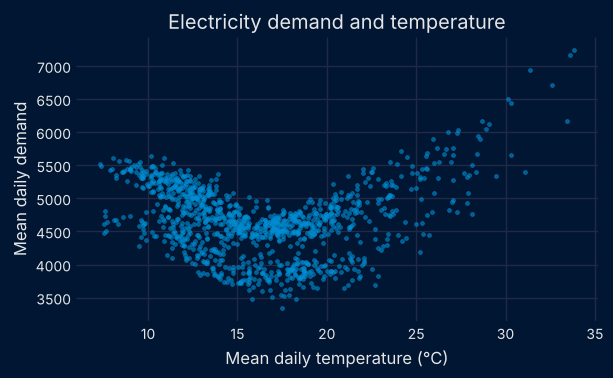

In [4]:
# Daily demand versus daily temperature
# ==============================================================================
set_dark_theme()
daily = data[["Demand", "Temperature"]].resample("D").mean()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(daily["Temperature"], daily["Demand"], s=8, alpha=0.6)
ax.set_xlabel("Mean daily temperature (°C)")
ax.set_ylabel("Mean daily demand")
ax.set_title("Electricity demand and temperature")
plt.show()

## Archive of forecasts

In production, the temperature of the coming days is only known through the forecasts that a weather service publishes periodically. The archive of these forecasts has one row per forecast value: the time it refers to (`timestamp`), the time it was published (`published_at`) and the value (`temperature`). Each timestamp appears many times, once for each forecast that covered it.

`vic_electricity` only contains the observed temperature, so the archive is simulated: a new forecast is published every 6 hours, 5 hours after the run of the weather model, and covers the next 8 days. Its error grows with the horizon and persists for a few hours, as in real forecasts. In a real project, this table is provided by the weather service or built by storing each forecast when it is received.

<div class="admonition note" name="html-admonition" style="background: rgba(0,184,212,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #00b8d4; border-color: #00b8d4; padding-left: 10px; padding-right: 10px;">

<p class="title">
    <i style="font-size: 18px; color:#00b8d4;"></i>
    <b style="color: #00b8d4;">✏️ Note</b>
</p>

The size and persistence of the simulated errors were calibrated with archived temperature forecasts for Melbourne (2023 and 2024) from <a href="https://open-meteo.com/" target="_blank">Open-Meteo</a> (CC BY 4.0): a standard deviation of 1.4 °C one day ahead, 1.7 °C three days ahead and 3.2 °C seven days ahead, and a correlation of 0.82 between the errors of consecutive hours.

</div>

In [5]:
# Simulated archive of temperature forecasts
# ==============================================================================
rng = np.random.default_rng(seed=123)
runs = pd.date_range(data.index[0] - pd.Timedelta(8, unit="D"), data.index[-1], freq="6h")
horizon = np.arange(1, 8 * 24 + 1)  # Hours after the run of the weather model
error_std = np.interp(
    horizon,
    [24, 48, 72, 96, 120, 144, 168],
    [1.40, 1.53, 1.70, 2.01, 2.42, 2.71, 3.18],
)

# Errors correlated over the horizon of each run
noise = rng.normal(size=(len(runs), len(horizon)))
error = np.empty_like(noise)
error[:, 0] = noise[:, 0]
for h in range(1, len(horizon)):
    error[:, h] = 0.82 * error[:, h - 1] + np.sqrt(1 - 0.82**2) * noise[:, h]

archive = pd.DataFrame({
    "run": np.repeat(runs, len(horizon)),
    "horizon": np.tile(horizon, len(runs)),
    "error": (error * error_std).ravel(),
})
archive["timestamp"] = archive["run"] + pd.to_timedelta(archive["horizon"], unit="h")
archive["published_at"] = archive["run"] + pd.Timedelta(5, unit="h")
archive = archive[
    archive["timestamp"].isin(data.index)
    & (archive["timestamp"] > archive["published_at"])
]
archive["temperature"] = (
    data.loc[archive["timestamp"], "Temperature"].to_numpy() + archive["error"]
).round(1)
archive = archive[["timestamp", "published_at", "temperature"]].reset_index(drop=True)
archive.head()

,timestamp,published_at,temperature
0,2012-01-01 00:00:00,2011-12-24 05:00:00,23.7
1,2012-01-01 00:00:00,2011-12-24 11:00:00,15.7
2,2012-01-01 01:00:00,2011-12-24 11:00:00,13.6
3,2012-01-01 02:00:00,2011-12-24 11:00:00,12.2
4,2012-01-01 03:00:00,2011-12-24 11:00:00,14.5


The forecasts for a given hour are revised as it gets closer. For example, these are the last forecasts published for 15:00 on 15 January 2014, a day of the January 2014 heatwave in Melbourne:

In [6]:
# Forecasts published for one hour
# ==============================================================================
timestamp = pd.Timestamp("2014-01-15 15:00")
print(f"Observed temperature: {data.loc[timestamp, 'Temperature']:.1f} °C")
archive[archive["timestamp"] == timestamp].tail(8)

Observed temperature: 37.3 °C


,timestamp,published_at,temperature
559191,2014-01-15 15:00:00,2014-01-13 17:00:00,37.5
559372,2014-01-15 15:00:00,2014-01-13 23:00:00,39.3
559553,2014-01-15 15:00:00,2014-01-14 05:00:00,39.2
559734,2014-01-15 15:00:00,2014-01-14 11:00:00,38.5
559915,2014-01-15 15:00:00,2014-01-14 17:00:00,35.6
560096,2014-01-15 15:00:00,2014-01-14 23:00:00,39.1
560277,2014-01-15 15:00:00,2014-01-15 05:00:00,36.0
560458,2014-01-15 15:00:00,2014-01-15 11:00:00,37.4


## Forecasting process and backtesting

The backtest must reproduce the way predictions are made in production. In this example, every Tuesday at 10:00 the hourly demand of the next 7 days, from Wednesday 00:00 to Tuesday 23:00, is forecast. At that time, the last observed value of demand is the one of 09:00, and the most recent temperature forecast is the last one published before 10:00. This process is defined with [`TimeSeriesFold`](https://skforecast.org/latest/api/model_selection#skforecast.model_selection._split.TimeSeriesFold):

- `steps=168`: 7 days of hourly predictions.
- `gap=14`: the hours from 10:00 to 23:00 of Tuesday are predicted but not evaluated.
- `fold_stride=168`: a new forecast every week.
- `initial_train_size`: the observations up to Tuesday 31 December 2013 at 09:00, so that the first forecast is made that day at 10:00 and the backtest covers 2014.
- `refit=False`: the model is trained once, with the data before the first forecast.

The forecaster uses as predictors the demand of the last 3 hours and of the same hours one day and one week before, together with the exogenous variables.

In [7]:
# Backtesting configuration and forecaster
# ==============================================================================
initial_train_size = len(data.loc[:"2013-12-31 09:00"])
cv = TimeSeriesFold(
    steps              = 7 * 24,
    gap                = 14,
    fold_stride        = 7 * 24,
    initial_train_size = initial_train_size,
    refit              = False,
    verbose            = False,
)
forecaster = ForecasterRecursive(
    estimator = LGBMRegressor(random_state=123, verbose=-1),
    lags      = [1, 2, 3, 23, 24, 25, 167, 168, 169],
)

## Backtesting with the observed temperature

The usual approach is to use the observed temperature as an exogenous variable, both to train the model and to make the predictions of the backtest. For reference, the same forecaster is first evaluated without temperature, using only the calendar features. Both backtests are run with [`backtesting_forecaster`](https://skforecast.org/latest/api/model_selection#skforecast.model_selection._validation.backtesting_forecaster).

In [8]:
# Backtesting without temperature
# ==============================================================================
metric_no_temperature, _ = backtesting_forecaster(
    forecaster = forecaster,
    y          = data["Demand"],
    exog       = data[calendar_features],
    cv         = cv,
    metric     = "mean_absolute_error",
)
mae_no_temperature = metric_no_temperature.at[0, "mean_absolute_error"]
print(f"MAE without temperature: {mae_no_temperature:.1f}")

100%|██████████| 52/52 [00:00<00:00, 114.02it/s]

MAE without temperature: 284.2


In [9]:
# Backtesting with the observed temperature
# ==============================================================================
exog_observed = data[calendar_features].assign(temperature=data["Temperature"])
metric_observed, _ = backtesting_forecaster(
    forecaster = forecaster,
    y          = data["Demand"],
    exog       = exog_observed,
    cv         = cv,
    metric     = "mean_absolute_error",
)
mae_observed = metric_observed.at[0, "mean_absolute_error"]
print(f"MAE with the observed temperature: {mae_observed:.1f}")

100%|██████████| 52/52 [00:00<00:00, 115.53it/s]

MAE with the observed temperature: 209.9


Temperature reduces the error considerably. However, this backtest predicts each week with the temperature observed during that week, which was not known on Tuesday at 10:00, so it underestimates the error the model will have in production.

## Backtesting with the temperature available at prediction time

For each hour, the point-in-time temperature is the last forecast published before the Tuesday at 10:00 when that hour is predicted. Since the forecast weeks go from Wednesday to Tuesday, this moment is 14 hours before the start of the week of each hour.

In [10]:
# Moment when each hour is predicted: Tuesday at 10:00 before its week
# ==============================================================================
days_since_wednesday = (data.index.dayofweek - 2) % 7
week_start = data.index.normalize() - pd.to_timedelta(days_since_wednesday, unit="D")
prediction_time = pd.Series(week_start - pd.Timedelta(14, unit="h"), index=data.index)
prediction_time.loc["2014-01-07 22:00":"2014-01-08 01:00"]

Time
2014-01-07 22:00:00   2013-12-31 10:00:00
2014-01-07 23:00:00   2013-12-31 10:00:00
2014-01-08 00:00:00   2014-01-07 10:00:00
2014-01-08 01:00:00   2014-01-07 10:00:00
Freq: h, Name: Time, dtype: datetime64[ns]

The hours of Tuesday 7 January 2014 are predicted on Tuesday 31 December 2013 at 10:00, and those of Wednesday 8 January, the first day of the next week, on Tuesday 7 January at 10:00. The following function selects, for each timestamp, the last value published at or before its prediction time.

In [11]:
# Point-in-time values of a forecasted variable
# ==============================================================================
def point_in_time(archive, prediction_time):
    """
    Last value of each timestamp published at or before its prediction time.
    """
    archive = archive.merge(
        prediction_time.rename("prediction_time"), left_on="timestamp", right_index=True
    )
    archive = archive[archive["published_at"] <= archive["prediction_time"]]
    values = archive.sort_values("published_at").groupby("timestamp")["temperature"].last()

    return values.reindex(prediction_time.index)


temperature_forecast = point_in_time(archive, prediction_time)
error = (temperature_forecast - data["Temperature"]).loc["2014"].abs().mean()
print(f"Mean absolute error of the temperature forecasts in 2014: {error:.2f} °C")

Mean absolute error of the temperature forecasts in 2014: 1.84 °C


The model is trained with the observed temperature, which is available for the whole history, and the predictions of the backtest use the forecasts. With `refit=False` the model is trained only once, with the data before the first forecast, so a single exogenous column can hold both: the observed temperature in the training period and the forecasts after it.

In [12]:
# Backtesting with the temperature available at prediction time
# ==============================================================================
is_train = np.arange(len(data)) < initial_train_size
exog_available = data[calendar_features].assign(
    temperature=data["Temperature"].where(is_train, temperature_forecast)
)
metric_available, predictions_available = backtesting_forecaster(
    forecaster = forecaster,
    y          = data["Demand"],
    exog       = exog_available,
    cv         = cv,
    metric     = "mean_absolute_error",
)
mae_available = metric_available.at[0, "mean_absolute_error"]
print(f"MAE with the temperature available at prediction time: {mae_available:.1f}")
print(f"Increase over the backtest with the observed temperature: {mae_available / mae_observed - 1:.1%}")

100%|██████████| 52/52 [00:00<00:00, 104.14it/s]

MAE with the temperature available at prediction time: 227.0
Increase over the backtest with the observed temperature: 8.1%


The error is 8.1% higher than in the backtest with the observed temperature (227.0 versus 209.9). This is the error to expect in production: the previous backtest made the model look better than it is. Even so, the forecasted temperature is still very useful: the error is 20% lower than without temperature (284.2).

<div class="admonition note" name="html-admonition" style="background: rgba(0,191,191,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #00bfa5; border-color: #00bfa5; padding-left: 10px; padding-right: 10px;">

<p class="title">
    <i style="font-size: 18px; color:#00bfa5;"></i>
    <b style="color: #00bfa5;">&#128161 Tip</b>
</p>

This approach only needs archived forecasts for the backtesting period. The training period, usually much longer, uses the observed values.

</div>

## Training with the forecasts

If the archive covers the whole history, the model can also be trained with the forecasts that were available at each moment, applying the same point-in-time rule to every hour. The model then learns how reliable the forecasts are, and the exogenous column is the same in training and prediction, so it also works with `refit=True`. The column of the previous section would not be valid with `refit=True`: the hours predicted with forecasts in one fold become training data in the following ones, where they should have the observed values.

In [13]:
# Backtesting with the model trained on the forecasts
# ==============================================================================
exog_forecast = data[calendar_features].assign(temperature=temperature_forecast)
metric_forecast, _ = backtesting_forecaster(
    forecaster = forecaster,
    y          = data["Demand"],
    exog       = exog_forecast,
    cv         = cv,
    metric     = "mean_absolute_error",
)
mae_forecast = metric_forecast.at[0, "mean_absolute_error"]
print(f"MAE with the model trained on the forecasts: {mae_forecast:.1f}")

100%|██████████| 52/52 [00:00<00:00, 114.17it/s]

MAE with the model trained on the forecasts: 238.9


In [14]:
# Summary of results
# ==============================================================================
results = pd.DataFrame({
    "temperature used to train": ["none", "observed", "observed", "forecasts"],
    "temperature used to predict": ["none", "observed", "forecasts", "forecasts"],
    "MAE": [mae_no_temperature, mae_observed, mae_available, mae_forecast],
})
results.round(1)

,temperature used to train,temperature used to predict,MAE
0,none,none,284.2
1,observed,observed,209.9
2,observed,forecasts,227.0
3,forecasts,forecasts,238.9


In this example, training with the observed temperature gives a lower error than training with the forecasts (227.0 versus 238.9). The result depends on the case: with less accurate forecasts, a model trained with them may learn better how much to rely on the variable. Both options should be compared with a backtest that predicts with the forecasts available at prediction time.

## Predicting in production

In production, the same steps are followed every Tuesday at 10:00: train the forecaster with the observed data (or use the one already trained), select the last temperature forecasts published before that moment and predict the next 7 days. Since the last observed value is the one of 09:00, the forecaster predicts 14 + 168 hours and the first 14 are discarded, as the `gap` does in the backtest.

The forecast of Tuesday 25 November 2014 is shown as an example. That week is included in the data, so the predictions can be compared with the observed demand.

In [15]:
# Forecast made on Tuesday 25 November 2014 at 10:00
# ==============================================================================
now = pd.Timestamp("2014-11-25 10:00")
train = data.loc[: now - pd.Timedelta(1, unit="h")]
forecaster.fit(
    y    = train["Demand"],
    exog = train[calendar_features].assign(temperature=train["Temperature"]),
)

future_index = pd.date_range(start=now, periods=14 + 7 * 24, freq="h")
latest_forecasts = point_in_time(archive, pd.Series(now, index=future_index))
exog_future = data.loc[future_index, calendar_features].assign(temperature=latest_forecasts)
predictions = forecaster.predict(steps=len(future_index), exog=exog_future).iloc[14:]
predictions.head(3)

2014-11-26 00:00:00    3957.274592
2014-11-26 01:00:00    3648.591584
2014-11-26 02:00:00    3476.183986
Freq: h, Name: pred, dtype: float64

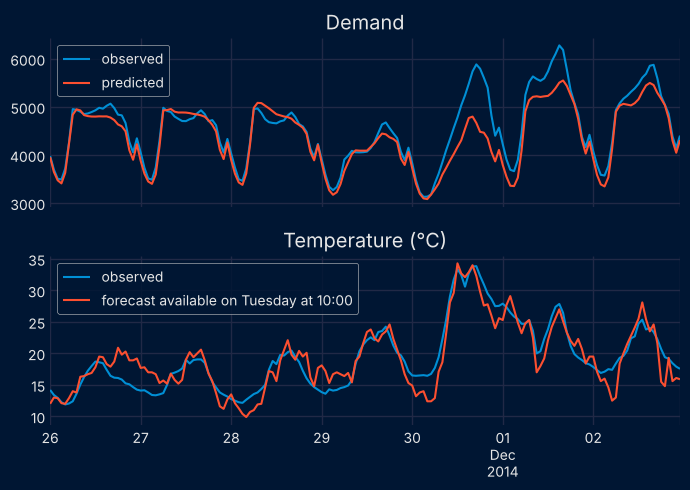

In [16]:
# Plot predictions and temperature forecasts used
# ==============================================================================
fig, axs = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
data.loc[predictions.index, "Demand"].plot(ax=axs[0], label="observed")
predictions.plot(ax=axs[0], label="predicted")
axs[0].set_title("Demand")
axs[0].legend()
data.loc[predictions.index, "Temperature"].plot(ax=axs[1], label="observed")
exog_future.loc[predictions.index, "temperature"].plot(
    ax=axs[1], label="forecast available on Tuesday at 10:00"
)
axs[1].set_title("Temperature (°C)")
axs[1].set_xlabel("")
axs[1].legend()
fig.tight_layout()
plt.show()

## Conclusions

- A backtest that predicts with the observed values of a forecasted exogenous variable is optimistic. In this example, the error in production is 8.1% higher than the one estimated with the observed temperature.
- To evaluate the model as it will work in production, build the exogenous variable with the last value published before each prediction and configure `TimeSeriesFold` (`steps`, `gap` and `fold_stride`) so that each fold reproduces the forecasting process.
- Training with the observed values only needs archived forecasts for the backtesting period, and requires `refit=False` in the backtest. Training with the forecasts needs archived forecasts for the whole history and works with any value of `refit`. Compare both options.
- The same approach applies to any exogenous variable that is a forecast: weather, prices, plans or the predictions of another model.

For more details, see the [Exogenous variables](../user_guides/exogenous-variables.html) and [Backtesting](../user_guides/backtesting.html) user guides.